# When to sell

Compare scheduled sale dates and storage economics for a real published pair.

In [1]:
import sys
from pathlib import Path

HERE = Path.cwd().resolve()
NB = HERE if (HERE / 'mandi_notes.py').is_file() else HERE / 'Notebook'
sys.path.insert(0, str(NB))
from mandi_notes import *

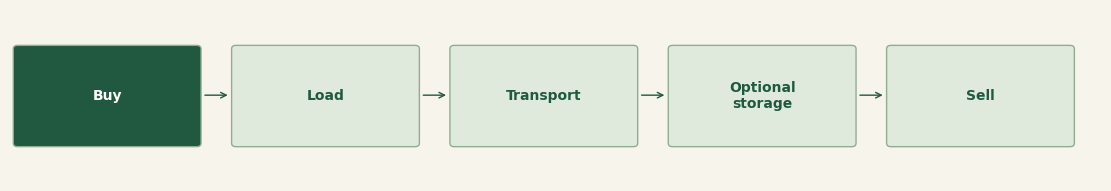

Tomato · Gudimalkapur APMC → Hindol APMC · replay starting 2026-11-13 08:00 IST


,Days stored,Buy,Storage starts,Sale,Quote basis,Price (₹/q),Storage (₹),Margin (₹),Screened margin (₹)
0,0,2026-11-13T08:00,,2026-11-14T06:39,persistence_assumption,3800.0,0,241985.00,168477.75
1,7,2026-11-13T08:00,2026-11-13T17:51,2026-11-21T22:40,persistence_assumption,3800.0,2100,227783.88,152861.94
2,14,2026-11-13T08:00,2026-11-13T17:51,2026-11-28T22:40,persistence_assumption,3800.0,4200,223625.62,148703.68
3,30,2026-11-13T08:00,2026-11-13T17:51,2026-12-14T22:40,persistence_assumption,3800.0,9000,214164.09,118676.53


In [2]:
diagram(["Buy", "Load", "Transport", "Optional\nstorage", "Sell"])
plan, stamp = planned_trade()
print(f"{plan['crop']} · {plan['buy']['market']} → {plan['sell']['market']} · replay starting {stamp:%Y-%m-%d %H:%M} IST")
options = pd.DataFrame([{
    "Days stored": r["storage_days"], "Buy": r["schedule"]["procurement_at"][:16],
    "Storage starts": (r["schedule"]["storage_start_at"] or "")[:16],
    "Sale": r["schedule"]["sale_at"][:16], "Quote basis": r["sale_quote"]["kind"],
    "Price (₹/q)": r["sale_price"], "Storage (₹)": r["storage"], "Margin (₹)": r["margin"],
    "Screened margin (₹)": r["risk_adjusted_margin"],
} for r in plan["timing_options"]]).sort_values("Days stored")
display(options)
if plan["timing_unavailable"]:
    display(pd.DataFrame(plan["timing_unavailable"]))

,Stored price change (%),Storage margin (₹),Recommended days stored
0,0,227783.88,0
1,1,231468.18,0
2,-10,190940.87,0
3,25,319891.43,7
4,75,504106.51,7


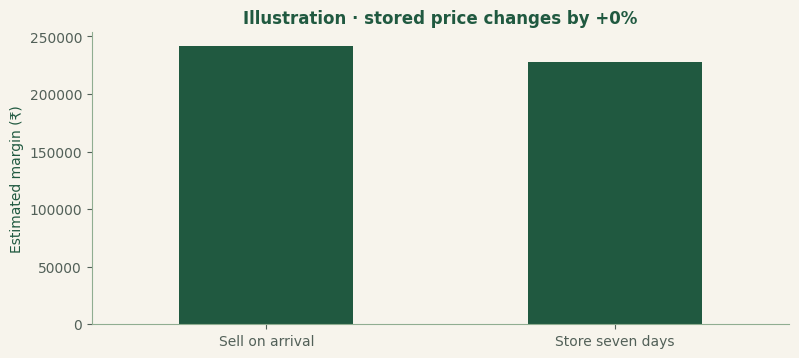

Screened recommendation: Sell on arrival


interactive(children=(Dropdown(description='Change', options=(0, 1, -10, 25, 75), value=0), Button(description…

In [3]:
from Code.intelligence import planning
from unittest.mock import patch

stored = next((r for r in plan["timing_options"] if r["storage_days"] == 7), None)
direct = next(r for r in plan["timing_options"] if r["storage_days"] == 0)
if stored:
    # Hypothetical price changes, applied only to the stored option's matching date.
    later = stored["sale_quote"]
    def outcome(change):
        hypothetical = {**later, "price": round(later["price"]*(1+change/100),2)}
        with patch.object(planning, "quote", return_value=hypothetical):
            simulated = planning.complete(stored, stamp.date(), stamp)
        ranking, _ = planning.rank([direct, simulated], planning.s.CONFIG["decision"])
        return simulated, ranking[0]

    def compare(change):
        simulated, winner = outcome(change)
        pd.Series({"Sell on arrival":direct["margin"],"Store seven days":simulated["margin"]}).plot.bar(
            rot=0, title=f"Illustration · stored price changes by {change:+g}%", ylabel="Estimated margin (₹)")
        plt.show()
        print("Screened recommendation:", "Store seven days" if winner["storage_days"] else "Sell on arrival")
    display(pd.DataFrame([
        {"Stored price change (%)": change, "Storage margin (₹)": result["margin"],
         "Recommended days stored": winner["storage_days"]}
        for change in [0,1,-10,25,75] for result,winner in [outcome(change)]
    ]))
    controls(compare, change=[0,1,-10,25,75])
else:
    print("Seven-day storage was infeasible for this pair. The controlled comparison requires a feasible stored plan.")

The replay uses published observations and saved routes. In a later calendar session, an exact-date operational quote may be unavailable, so the planner labels the carried-forward assumption. Procurement and sale dates include the modeled loading, driving, and storage time. The price-change control is an illustration.

**Takeaway** · Flat quotes leave storage expenses and losses to recover. A later sale can win when the price gain covers them.

**Next** · Trace publication into the application in Notebook 13.